# Holdout Backtesting

## Load Backtest Inputs

- **Purpose:** Load and validate inputs for comparing three tuned meta families with one selected primary configuration; run meta modeling first. This notebook is independent of other backtesting notebooks.
- **Input:** Prepared events, split manifest, primary model, meta-model bundle, saved predictions, and market data.
- **Output:** Validated backtest inputs in memory for the following prediction, sizing, simulation, and statistics stages.
- **STRATEGY:** `sentiment_synchronous` — Choose the matching model artifacts and execution rules.
- **PARTITION:** `holdout` — Use the fixed holdout evaluation window.
- **MANIFEST_PATH:** `data/preprocessing/universe/sp500_2025.csv` — Fix the research universe across stages.
- **DATA_START:** `2025-01-01 UTC` — Include January preparation observations before the research period.
- **RESEARCH_START:** `2025-02-01 UTC` — Set the inclusive research start and the first date in artifact filenames.
- **RESEARCH_END:** `2026-01-01 UTC` — Set the exclusive research end; artifact filenames use the preceding date.
- **settings:** `max_positions_per_side=10`, `initial_aum=100_000.0`, `broker_fee_bps=1.0`, `slippage_bps=1.0` — Set the total position limit per direction across both books, initial capital, and trading costs. The limit must be a positive even integer; 10 assigns 5 longs and 5 shorts to each book. Positions in the same symbol in different books count separately.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src.backtesting.backtesting_workflow import (
    load_backtest_inputs, development_predictions, holdout_predictions,
    prepare_bet_sizing, simulate_portfolios, summarize_backtests, save_backtest_results,
)
from src.backtesting.portfolio_management import PortfolioSettings
from src.preprocessing.market_data import ResearchPaths

PROJECT_ROOT = Path.cwd().resolve().parents[2]

STRATEGY = "sentiment_synchronous"
PARTITION = "holdout"

MANIFEST_PATH = PROJECT_ROOT / "data/preprocessing/universe/sp500_2025.csv"

DATA_START = pd.Timestamp("2025-01-01", tz="UTC")
RESEARCH_START = pd.Timestamp("2025-02-01", tz="UTC")
RESEARCH_END = pd.Timestamp("2026-01-01", tz="UTC")

settings = PortfolioSettings(
    max_positions_per_side=10,
    initial_aum=100_000.0, broker_fee_bps=1.0, slippage_bps=1.0,
)

paths = ResearchPaths(PROJECT_ROOT, model_kind="sentiment", start=RESEARCH_START, end=RESEARCH_END)

In [2]:
inputs = load_backtest_inputs(
    paths, settings, strategy=STRATEGY, partition=PARTITION,
    manifest_path=MANIFEST_PATH,
    data_start=DATA_START, end=RESEARCH_END,
)

## Holdout Predictions

- **Purpose:** Validate saved holdout predictions without refitting, tuning, or selecting a winner on holdout.
- **Input:** Family-tagged holdout predictions, fixed event/partition keys, and canonical primary predictions.
- **Output:** Validated predictions in memory; missing/duplicate events, mixed partitions, or inconsistent primary predictions are rejected.

In [3]:
validation_settings = None
splits = None
predictions = holdout_predictions(inputs)

## Bet Sizing

- **Purpose:** Select the latest eligible signal per symbol and rank take probabilities at scheduled open/close entries, with a one-minute information cutoff.
- **Input:** Family/path predictions and the session entry/exit schedule.
- **Output:** In-memory selections with equal weights within each side (half the book per side); exclude entries without an exit inside evaluation bounds.

In [4]:
prepared = prepare_bet_sizing(inputs, predictions, splits)

## Portfolio Management

- **Purpose:** Execute independent family/path accounts using a shared price index and scheduled decisions/fills.
- **Input:** Prepared signals/calibration and existing dollar bars.
- **Output:** In-memory ledgers, trades, exposures, and exclusions; progress counts completed scheduled session decisions.
- **Execution:** See the [execution contract](../../../docs/api/backtesting/portfolio_management.md#synchronous-scheduled-execution) for next-bar fills, book rollover, and final-bar liquidation.
- **Migration:** Recompute backtest results after loading the updated module; existing model artifacts remain reusable.
- **Recording:** Engine v3 records session open/close, fills, terminal processing and evaluation boundaries; all trades and daily results are retained. Minute sampling is removed, so intraday statistics use this sparse grid.
- **Reload:** Load the updated modules before rerunning; an already running cell continues with its existing engine.


In [5]:
accounts = simulate_portfolios(inputs, prepared, show_progress=True)

Preparing synchronous price index


Synchronous decisions:   0%|          | 0/93 [00:00<?, ?decision/s]

## Backtest Statistics

- **Purpose:** Summarize account, classification, and holding metrics without resimulating.
- **Input:** Existing accounts, out-of-sample predictions, and returns for the selected benchmark symbol.
- **Output:** Three model-family statistics tables and three cumulative-return graphs; save `statistics.parquet` and `settings.json` under `data/backtesting/sentiment_synchronous/holdout`. Account curves, detailed trades, and intermediate predictions remain in memory; see the [storage decision](../../../docs/decisions.md#12-database).
- **Display:** For each model family (Boosting, Bagging, Random Forest), show only `general_characteristics`, `performance`, `runs`, `implementation_shortfall`, `efficiency`, and `classification_scores` in this code-definition order by path, followed by its path return curves. Rows identify section, metric, and unit; classification metric names use `primary_` or `meta_` prefixes instead of an entity column; no rows or columns are abbreviated. Within each section, retain the original metric order. Other sections remain in the saved statistics. Rerun only the display cell when `statistics` and `accounts` are already available.
- **benchmark_symbol:** `SPY` — Select the market benchmark; local dollar bars must cover the evaluation interval and provide a starting anchor.
- **periods_per_year:** `365.25` — Annualize the calendar-day account series.
- **annual_risk_free_rate:** `0.03` — Use the assumed annual risk-free rate in risk-adjusted statistics.
- **annualized_benchmark_sharpe_ratio:** `1.0` — Set the reference Sharpe for probabilistic Sharpe evaluation.

In [6]:
evaluation_settings = dict(
    benchmark_symbol="SPY",
    periods_per_year=365.25, annual_risk_free_rate=0.03,
    annualized_benchmark_sharpe_ratio=1.0,
)

statistics = summarize_backtests(inputs, predictions, accounts, **evaluation_settings)

### Boosting: Backtest Statistics

holdout
section                  metric                          unit                                        
general_characteristics  start                           timestamp   2025-10-24T13:51:24.469462+00:00
                         end                             timestamp          2025-12-31T21:00:00+00:00
                         average_aum                     USD                        99418.83049527885
                         leverage                        ratio                    0.48201608249503164
                         maximum_dollar_position_size    USD                        73822.02311373508
                         ratio_of_longs                  ratio                     0.5068807339449541
                         frequency_of_bets               count/year                 2331.691333115143
                         average_holding_period          days                       1.463542807986111
                         annualized_turnover             ratio                     239.95288046625544
                         correlation_to_underlying       ratio                     0.3168500915473121
performance              pnl                             USD                      -1583.2624647268967
                         annualized_rate_of_return       ratio                    -0.0818082126772195
                         pnl_from_long_positions         USD                       -601.0262314403208
                         pnl_from_short_positions        USD                       -982.2362332866096
                         hit_ratio                       ratio                     0.4793577981651376
                         average_return_from_hits        ratio                   0.001515669664572132
                         average_return_from_misses      ratio                 -0.0015317811619995451
runs                     hhi_positive_returns            ratio                   0.004332766515122922
                         hhi_negative_returns            ratio                   0.004274502308206049
                         hhi_time_between_bets           ratio                    0.10771399713828812
                         percentile_drawdown             ratio                   0.010048461460169134
                         percentile_time_under_water     years                    0.01642713397058078
implementation_shortfall broker_fees_per_turnover        ratio                 0.00010000000154930154
                         average_slippage_per_turnover   ratio                 0.00010000000000000042
                         dollar_performance_per_turnover ratio                -0.00035493012926778603
                         return_on_execution_costs       ratio                    -1.7746506325915816
efficiency               sharpe_ratio                    ratio                   -0.11649475545078054
                         annualized_sharpe_ratio         ratio                    -2.2263912491660016
                         probabilistic_sharpe_ratio      ratio                    0.07589973684015909
classification_scores    primary_accuracy                score                     0.5804231555028133
                         primary_precision               score                     0.5582673200838135
                         primary_recall                  score                      0.789205171608297
                         primary_f1_score                score                     0.6539464944427551
                         primary_negative_log_loss       score                    -0.6716169534645025
                         meta_accuracy                   score                     0.5805598564886651
                         meta_precision                  score                      0.580502510768326
                         meta_recall                     score                                    1.0
                         meta_f1_score                   score                     0.7345796755313317
              

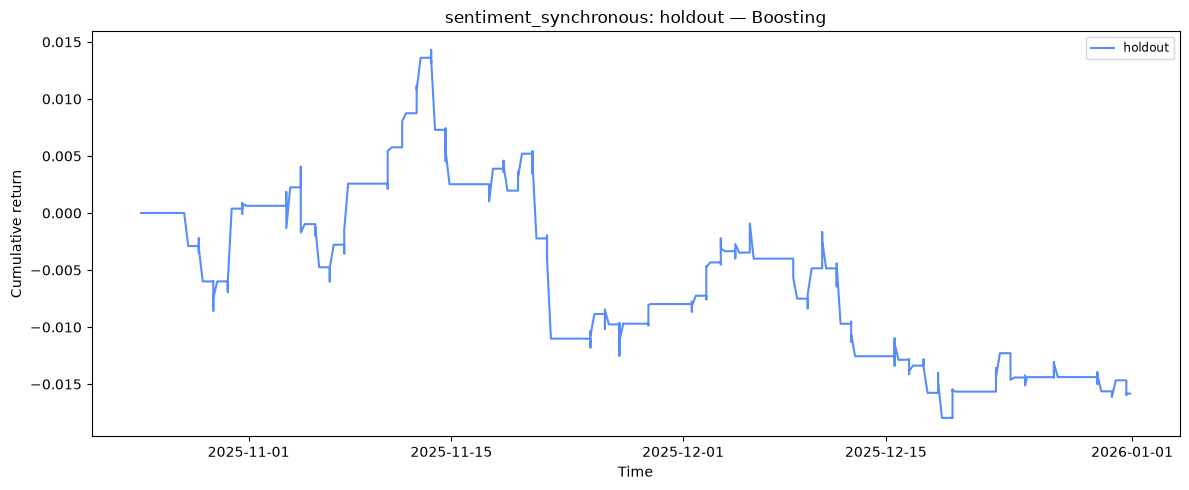

### Bagging: Backtest Statistics

holdout
section                  metric                          unit                                        
general_characteristics  start                           timestamp   2025-10-24T13:51:24.469462+00:00
                         end                             timestamp          2025-12-31T21:00:00+00:00
                         average_aum                     USD                        99608.23533022392
                         leverage                        ratio                    0.48243960060339697
                         maximum_dollar_position_size    USD                        74366.45488691068
                         ratio_of_longs                  ratio                     0.5115740740740741
                         frequency_of_bets               count/year                 2310.299669508582
                         average_holding_period          days                      1.4585480705368012
                         annualized_turnover             ratio                       240.379953627981
                         correlation_to_underlying       ratio                    0.23494347184443118
performance              pnl                             USD                       -1257.622241805555
                         annualized_rate_of_return       ratio                   -0.06544339020165646
                         pnl_from_long_positions         USD                      -1028.2701283245442
                         pnl_from_short_positions        USD                       -229.3521134811017
                         hit_ratio                       ratio                    0.49537037037037035
                         average_return_from_hits        ratio                  0.0014744668128177092
                         average_return_from_misses      ratio                  -0.001558216472460096
runs                     hhi_positive_returns            ratio                  0.0034515390401200488
                         hhi_negative_returns            ratio                  0.0046304331598603565
                         hhi_time_between_bets           ratio                    0.11136831275720162
                         percentile_drawdown             ratio                   0.020905603808303624
                         percentile_time_under_water     years                    0.09829454577352517
implementation_shortfall broker_fees_per_turnover        ratio                 0.00010000000080893214
                         average_slippage_per_turnover   ratio                   9.99999999999996e-05
                         dollar_performance_per_turnover ratio                 -0.0002808932386493682
                         return_on_execution_costs       ratio                    -1.4044661875662545
efficiency               sharpe_ratio                    ratio                   -0.09110526289880463
                         annualized_sharpe_ratio         ratio                    -1.7411595851331312
                         probabilistic_sharpe_ratio      ratio                    0.10661246846867772
classification_scores    primary_accuracy                score                     0.5804231555028133
                         primary_precision               score                     0.5582673200838135
                         primary_recall                  score                      0.789205171608297
                         primary_f1_score                score                     0.6539464944427551
                         primary_negative_log_loss       score                    -0.6716169534645025
                         meta_accuracy                   score                     0.5874018800901489
                         meta_precision                  score                     0.5923554201497354
                         meta_recall                     score                     0.9272610141971865
                         meta_f1_score                   score                     0.7229035896670866
              

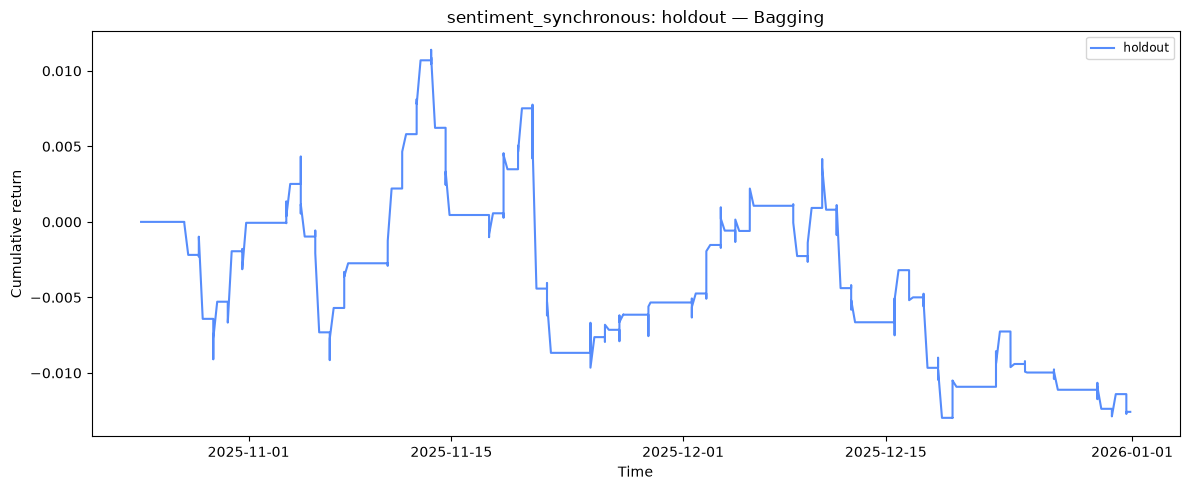

### Random Forest: Backtest Statistics

holdout
section                  metric                          unit                                        
general_characteristics  start                           timestamp   2025-10-24T13:51:24.469462+00:00
                         end                             timestamp          2025-12-31T21:00:00+00:00
                         average_aum                     USD                        100989.9011443492
                         leverage                        ratio                     0.4368524781018571
                         maximum_dollar_position_size    USD                       53709.705170783156
                         ratio_of_longs                  ratio                     0.5545454545454546
                         frequency_of_bets               count/year                1764.8122475412779
                         average_holding_period          days                      1.4581597891800644
                         annualized_turnover             ratio                      216.0457878706912
                         correlation_to_underlying       ratio                     0.3464978212268609
performance              pnl                             USD                       1518.9206055190589
                         annualized_rate_of_return       ratio                    0.08395876118604217
                         pnl_from_long_positions         USD                       148.36811697183202
                         pnl_from_short_positions        USD                        1370.552488547286
                         hit_ratio                       ratio                     0.5272727272727272
                         average_return_from_hits        ratio                  0.0018361010189142264
                         average_return_from_misses      ratio                 -0.0018457159275215467
runs                     hhi_positive_returns            ratio                  0.0076469083239626085
                         hhi_negative_returns            ratio                   0.008148919000755886
                         hhi_time_between_bets           ratio                    0.10415977961432511
                         percentile_drawdown             ratio                    0.01496142942618238
                         percentile_time_under_water     years                   0.053034262427348725
implementation_shortfall broker_fees_per_turnover        ratio                  9.999999427697515e-05
                         average_slippage_per_turnover   ratio                  9.999999999999972e-05
                         dollar_performance_per_turnover ratio                    0.00037230244839393
                         return_on_execution_costs       ratio                      1.861512295237058
efficiency               sharpe_ratio                    ratio                    0.04092292193057496
                         annualized_sharpe_ratio         ratio                     0.7820990303295673
                         probabilistic_sharpe_ratio      ratio                     0.4621197704305864
classification_scores    primary_accuracy                score                     0.5804231555028133
                         primary_precision               score                     0.5582673200838135
                         primary_recall                  score                      0.789205171608297
                         primary_f1_score                score                     0.6539464944427551
                         primary_negative_log_loss       score                    -0.6716169534645025
                         meta_accuracy                   score                     0.5365463321748782
                         meta_precision                  score                     0.6536392540758074
                         meta_recall                     score                     0.4286805683651252
                         meta_f1_score                   score                     0.5177812345911563
              

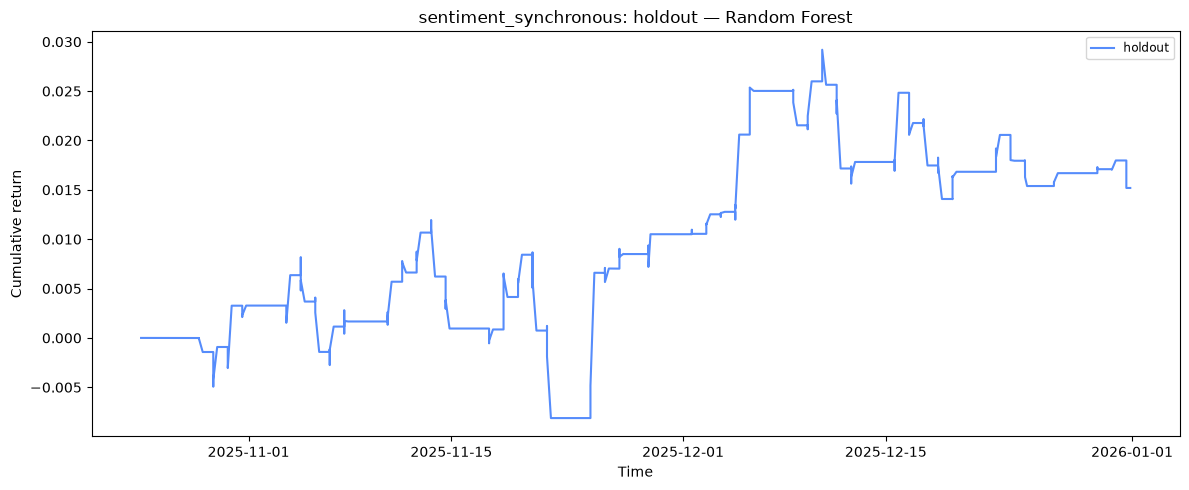

In [7]:
from IPython.display import Markdown

for family in ("boosting", "bagging", "random_forest"):
    family_name = family.replace("_", " ").title()
    family_statistics = statistics.loc[statistics["model_family"].eq(family)].set_index(
        ["section", "metric", "unit"],
    )
    display_values = family_statistics.drop(columns="model_family")
    display(Markdown(f"### {family_name}: Backtest Statistics"))
    with pd.option_context(
        "display.max_rows", None, "display.max_columns", None,
        "display.max_colwidth", None,
    ):
        display(display_values)

    fig, ax = plt.subplots(figsize=(12, 5))
    for (account_family, path), result in accounts.items():
        if account_family == family:
            ledger = result["ledger"]
            ax.plot(ledger.timestamp, ledger.aum / settings.initial_aum - 1, label=path)
    ax.set(
        title=f"{STRATEGY}: {PARTITION} — {family_name}",
        ylabel="Cumulative return", xlabel="Time",
    )
    ax.legend(fontsize="small", ncol=3)
    fig.tight_layout()
    plt.show()

In [8]:
result_directory = save_backtest_results(
    inputs, statistics,
    evaluation_settings=evaluation_settings, validation_settings=validation_settings,
)
print(result_directory)

/Users/kwonjunhyuk9/Documents/financial-machine-learning/data/backtesting/sentiment_synchronous/holdout
